<a href="https://colab.research.google.com/github/fabricioagn/Proj_TCC/blob/main/trab_ia.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Esteira de Aprendizado de Máquina — Coluna Vertebral

**Base utilizada como referência:** notebook `3_6_machinelearning.ipynb` (Lab 3.6 — Student Notebook).  
**Problema:** classificação binária de pacientes em *Normal* ou *Abnormal* (anormal).  
**Origem dos dados:** UCI Machine Learning Repository — Vertebral Column.

Este projeto adapta a sequência didática do notebook de referência: exploração dos resultados, matriz de confusão, métricas de desempenho (sensibilidade, especificidade, precisão, valor preditivo negativo, taxas de falsos positivos/negativos), acurácia e curva ROC/AUC. A execução foi adaptada para Python local, sem depender de AWS SageMaker ou de um bucket S3.

**Atenção:** antes de entregar, verifique na planilha da turma se esta base ainda não foi escolhida por outra pessoa.

## 1. Cenário e descrição da base

O conjunto contém seis atributos biomecânicos relacionados à coluna vertebral. A classificação binária agrupa os pacientes em:

- **Normal:** paciente sem anormalidade;
- **Abnormal:** paciente com anormalidade (Hérnia de Disco ou Espondilolistese).

A base original também permite uma classificação em três categorias, mas este trabalho utiliza a versão binária `column_2C_weka.arff`, conforme o notebook de referência.

Fonte: https://archive.ics.uci.edu/dataset/212/vertebral+column

## 2. Importação das bibliotecas

In [5]:
import warnings
warnings.filterwarnings("ignore")

import io
import zipfile
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.io import arff
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay, accuracy_score,
    classification_report, roc_auc_score, roc_curve, auc
)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## 3. Carregamento dos dados

In [6]:
# Download do arquivo compactado diretamente do repositório UCI.
url = "https://archive.ics.uci.edu/static/public/212/vertebral+column.zip"
resposta = requests.get(url, timeout=60)
resposta.raise_for_status()

arquivo_zip = zipfile.ZipFile(io.BytesIO(resposta.content))
print("Arquivos disponíveis:", arquivo_zip.namelist())

# Localiza o arquivo ARFF da classificação binária.
nome_arff = next(
    nome for nome in arquivo_zip.namelist()
    if nome.lower().endswith("column_2c_weka.arff")
)

with arquivo_zip.open(nome_arff) as arquivo_binario:
    # Envolve o arquivo binário em um leitor de texto com codificação UTF-8
    with io.TextIOWrapper(arquivo_binario, encoding="utf-8") as arquivo_texto:
        dados, metadados = arff.loadarff(arquivo_texto)

df = pd.DataFrame(dados)

# Converte a classe textual do arquivo ARFF para texto normal.
df["class"] = df["class"].str.decode("utf-8")

# Mapeamento compatível com o notebook de referência:
# Abnormal = 1 e Normal = 0.
df["class"] = df["class"].map({"Abnormal": 1, "Normal": 0}).astype(int)

# Renomeia a variável-alvo para deixar seu significado explícito.
df = df.rename(columns={"class": "diagnostico"})

display(df.head())
print("Dimensões da base:", df.shape)

Arquivos disponíveis: ['column_2C.dat', 'column_2C_weka.arff', 'column_3C.dat', 'column_3C_weka.arff']


,pelvic_incidence,pelvic_tilt,lumbar_lordosis_angle,sacral_slope,pelvic_radius,degree_spondylolisthesis,diagnostico
0,63.027817,22.552586,39.609117,40.475232,98.672917,-0.254400,1
1,39.056951,10.060991,25.015378,28.995960,114.405425,4.564259,1
2,68.832021,22.218482,50.092194,46.613539,105.985135,-3.530317,1
3,69.297008,24.652878,44.311238,44.644130,101.868495,11.211523,1
4,49.712859,9.652075,28.317406,40.060784,108.168725,7.918501,1


Dimensões da base: (310, 7)


## 4. Estatísticas descritivas gerais

In [7]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
pelvic_incidence,310.0,60.496653,17.236520,26.147921,46.430294,58.691038,72.877696,129.834041
pelvic_tilt,310.0,17.542822,10.008330,-6.554948,10.667069,16.357689,22.120395,49.431864
lumbar_lordosis_angle,310.0,51.930930,18.554064,14.000000,37.000000,49.562398,63.000000,125.742385
sacral_slope,310.0,42.953831,13.423102,13.366931,33.347122,42.404912,52.695888,121.429566
pelvic_radius,310.0,117.920655,13.317377,70.082575,110.709196,118.268178,125.467674,163.071041
degree_spondylolisthesis,310.0,26.296694,37.559027,-11.058179,1.603727,11.767934,41.287352,418.543082
diagnostico,310.0,0.677419,0.468220,0.000000,0.000000,1.000000,1.000000,1.000000


Distribuição das classes:


,quantidade
diagnostico,
Abnormal,210
Normal,100


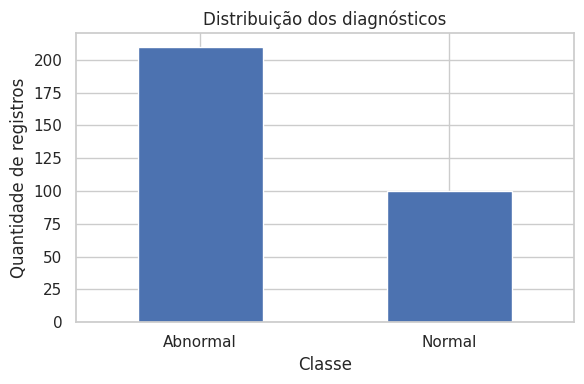

In [8]:
print("Distribuição das classes:")
display(
    df["diagnostico"]
      .map({0: "Normal", 1: "Abnormal"})
      .value_counts()
      .rename_axis("diagnostico")
      .to_frame("quantidade")
)

ax = df["diagnostico"].map({0: "Normal", 1: "Abnormal"}).value_counts().plot(
    kind="bar", rot=0, figsize=(6, 4)
)
ax.set_title("Distribuição dos diagnósticos")
ax.set_xlabel("Classe")
ax.set_ylabel("Quantidade de registros")
plt.tight_layout()
plt.show()

## 5. Preparação e transformação dos dados

### 5.1 Transformação nas linhas
Removemos linhas duplicadas e registros com valores ausentes. O notebook apresenta a quantidade removida em cada operação.

### 5.2 Transformação nas colunas
As seis características são numéricas. Aplicaremos `StandardScaler` para padronizar as colunas. A transformação fica dentro de um `Pipeline`, para que média e desvio-padrão sejam calculados somente a partir do conjunto de treinamento, evitando vazamento de dados.

In [9]:
qtd_inicial = len(df)

# Transformação de linhas: eliminar observações duplicadas.
df = df.drop_duplicates().copy()
duplicadas_removidas = qtd_inicial - len(df)

# Remover linhas com valores ausentes.
qtd_antes_na = len(df)
df = df.dropna().copy()
ausentes_removidas = qtd_antes_na - len(df)

print("Linhas duplicadas removidas:", duplicadas_removidas)
print("Linhas com valores ausentes removidas:", ausentes_removidas)
print("Total de linhas após a preparação:", len(df))

Linhas duplicadas removidas: 0
Linhas com valores ausentes removidas: 0
Total de linhas após a preparação: 310


In [10]:
X = df.drop(columns=["diagnostico"])
y = df["diagnostico"]

print("Características:", list(X.columns))
print("Total de características:", X.shape[1])
print("Valores ausentes restantes:", int(X.isna().sum().sum()))

Características: ['pelvic_incidence', 'pelvic_tilt', 'lumbar_lordosis_angle', 'sacral_slope', 'pelvic_radius', 'degree_spondylolisthesis']
Total de características: 6
Valores ausentes restantes: 0


## 6. Separação em treinamento, validação e teste

A divisão é estratificada para manter a proporção entre pacientes normais e anormais nos três subconjuntos:

- 60% para treinamento;
- 20% para validação;
- 20% para teste.

O conjunto de teste fica reservado para a avaliação final.

In [11]:
# 20% separados para teste.
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

# 25% dos 80% restantes = 20% da base total para validação.
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25,
    random_state=RANDOM_STATE, stratify=y_temp
)

total = len(X)
print(f"Treinamento: {len(X_train)} registros ({len(X_train)/total:.1%})")
print(f"Validação:   {len(X_val)} registros ({len(X_val)/total:.1%})")
print(f"Teste:       {len(X_test)} registros ({len(X_test)/total:.1%})")

Treinamento: 186 registros (60.0%)
Validação:   62 registros (20.0%)
Teste:       62 registros (20.0%)


In [12]:
distribuicao = pd.DataFrame({
    "treinamento": y_train.value_counts(normalize=True),
    "validação": y_val.value_counts(normalize=True),
    "teste": y_test.value_counts(normalize=True)
}).rename(index={0: "Normal", 1: "Abnormal"})
display(distribuicao)

,treinamento,validação,teste
diagnostico,,,
Abnormal,0.677419,0.677419,0.677419
Normal,0.322581,0.322581,0.322581


## 7. Treinamento do modelo

Será utilizado o algoritmo **Random Forest** para classificar os pacientes. A padronização e o classificador são reunidos em um `Pipeline`.

A classe positiva será **Abnormal (1)**. Para manter a lógica do notebook de referência, as probabilidades serão convertidas em classes usando inicialmente o limiar (*threshold*) de 0,30. O limiar será aplicado na validação e no teste.

In [13]:
modelo = Pipeline(steps=[
    ("padronizacao", StandardScaler()),
    ("classificador", RandomForestClassifier(
        n_estimators=200,
        random_state=RANDOM_STATE,
        class_weight="balanced"
    ))
])

modelo.fit(X_train, y_train)
print("Modelo treinado com sucesso.")

Modelo treinado com sucesso.


## 8. Validação e escolha do limiar

O modelo retorna probabilidades. A função abaixo converte a probabilidade de classe positiva (Abnormal) em 0 ou 1. O conjunto de validação é usado para observar o desempenho antes da avaliação final.

In [14]:
THRESHOLD = 0.30

def binary_convert(probabilidade, threshold=THRESHOLD):
    return 1 if probabilidade >= threshold else 0

prob_val = modelo.predict_proba(X_val)[:, 1]
pred_val = np.array([binary_convert(p) for p in prob_val])

print(f"Acurácia na validação (threshold={THRESHOLD}): "
      f"{accuracy_score(y_val, pred_val):.4f}")
print("\nRelatório de classificação — validação:")
print(classification_report(
    y_val, pred_val, labels=[0, 1],
    target_names=["Normal", "Abnormal"], zero_division=0
))

Acurácia na validação (threshold=0.3): 0.7742

Relatório de classificação — validação:
              precision    recall  f1-score   support

      Normal       0.80      0.40      0.53        20
    Abnormal       0.77      0.95      0.85        42

    accuracy                           0.77        62
   macro avg       0.78      0.68      0.69        62
weighted avg       0.78      0.77      0.75        62



## 9. Avaliação no conjunto de teste

Agora aplicamos o modelo ao conjunto de teste, que não participou do treinamento nem da escolha do limiar. A matriz de confusão compara os rótulos reais com as classes previstas.

Convenção usada: classe 0 = Normal; classe 1 = Abnormal.

In [15]:
prob_test = modelo.predict_proba(X_test)[:, 1]
pred_test = np.array([binary_convert(p) for p in prob_test])

test_labels = y_test
matriz = confusion_matrix(test_labels, pred_test, labels=[0, 1])
df_confusion = pd.DataFrame(
    matriz,
    index=["Real: Normal", "Real: Abnormal"],
    columns=["Previsto: Normal", "Previsto: Abnormal"]
)
display(df_confusion)

acuracia = accuracy_score(test_labels, pred_test)
print(f"Acurácia no teste: {acuracia:.4f} ({acuracia:.2%})")
print("\nRelatório de classificação — teste:")
print(classification_report(
    test_labels, pred_test, labels=[0, 1],
    target_names=["Normal", "Abnormal"], zero_division=0
))

,Previsto: Normal,Previsto: Abnormal
Real: Normal,11,9
Real: Abnormal,1,41


Acurácia no teste: 0.8387 (83.87%)

Relatório de classificação — teste:
              precision    recall  f1-score   support

      Normal       0.92      0.55      0.69        20
    Abnormal       0.82      0.98      0.89        42

    accuracy                           0.84        62
   macro avg       0.87      0.76      0.79        62
weighted avg       0.85      0.84      0.83        62



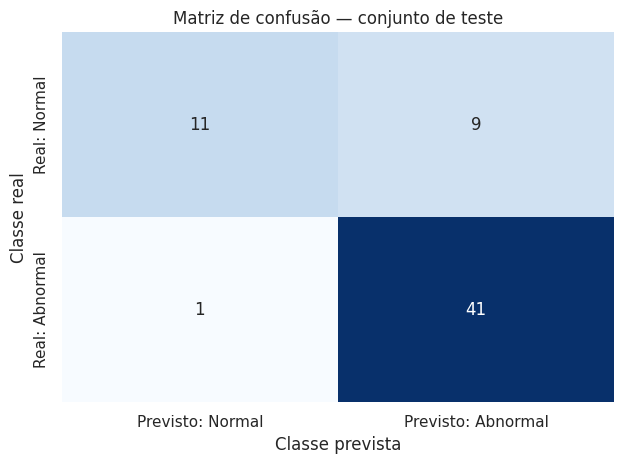

In [16]:
sns.heatmap(df_confusion, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Matriz de confusão — conjunto de teste")
plt.ylabel("Classe real")
plt.xlabel("Classe prevista")
plt.tight_layout()
plt.show()

## 10. Métricas calculadas a partir da matriz de confusão

A matriz fornece quatro valores:

- **TN (True Negative):** normal corretamente classificado como normal;
- **FP (False Positive):** normal classificado incorretamente como anormal;
- **FN (False Negative):** anormal classificado incorretamente como normal;
- **TP (True Positive):** anormal corretamente classificado como anormal.

Como a classe positiva é Abnormal, a sensibilidade mede a capacidade de identificar pacientes anormais.

In [17]:
TN, FP, FN, TP = matriz.ravel()

print(f"True Negative (TN): {TN}")
print(f"False Positive (FP): {FP}")
print(f"False Negative (FN): {FN}")
print(f"True Positive (TP): {TP}")

True Negative (TN): 11
False Positive (FP): 9
False Negative (FN): 1
True Positive (TP): 41


### 10.1 Sensibilidade (Recall / TPR)

In [18]:
sensibilidade = TP / (TP + FN) if (TP + FN) else 0
print(f"Sensibilidade: {sensibilidade:.2%}")
print("Interpretação: proporção dos pacientes anormais que foram identificados corretamente.")

Sensibilidade: 97.62%
Interpretação: proporção dos pacientes anormais que foram identificados corretamente.


### 10.2 Especificidade (TNR)

In [19]:
especificidade = TN / (TN + FP) if (TN + FP) else 0
print(f"Especificidade: {especificidade:.2%}")
print("Interpretação: proporção dos pacientes normais que foram identificados corretamente.")

Especificidade: 55.00%
Interpretação: proporção dos pacientes normais que foram identificados corretamente.


### 10.3 Precisão (Positive Predictive Value)

In [20]:
precisao = TP / (TP + FP) if (TP + FP) else 0
print(f"Precisão: {precisao:.2%}")

Precisão: 82.00%


### 10.4 Valor preditivo negativo (NPV)

In [21]:
npv = TN / (TN + FN) if (TN + FN) else 0
print(f"Valor preditivo negativo: {npv:.2%}")

Valor preditivo negativo: 91.67%


### 10.5 Taxa de falsos positivos (FPR)

In [22]:
fpr_taxa = FP / (FP + TN) if (FP + TN) else 0
print(f"Taxa de falsos positivos: {fpr_taxa:.2%}")

Taxa de falsos positivos: 45.00%


### 10.6 Taxa de falsos negativos (FNR)

In [23]:
fnr_taxa = FN / (TP + FN) if (TP + FN) else 0
print(f"Taxa de falsos negativos: {fnr_taxa:.2%}")

Taxa de falsos negativos: 2.38%


### 10.7 Taxa de falsas descobertas (FDR)

In [24]:
fdr_taxa = FP / (TP + FP) if (TP + FP) else 0
print(f"Taxa de falsas descobertas: {fdr_taxa:.2%}")

Taxa de falsas descobertas: 18.00%


### 10.8 Acurácia geral

In [25]:
print(f"Acurácia: {acuracia:.2%}")

Acurácia: 83.87%


### Resumo das métricas

In [26]:
metricas = pd.Series({
    "Sensibilidade (TPR)": sensibilidade,
    "Especificidade (TNR)": especificidade,
    "Precisão": precisao,
    "Valor preditivo negativo": npv,
    "Taxa de falsos positivos (FPR)": fpr_taxa,
    "Taxa de falsos negativos (FNR)": fnr_taxa,
    "Taxa de falsas descobertas (FDR)": fdr_taxa,
    "Acurácia": acuracia
}).to_frame("valor")
metricas["percentual"] = metricas["valor"].map(lambda x: f"{x:.2%}")
display(metricas[["percentual"]])

,percentual
Sensibilidade (TPR),97.62%
Especificidade (TNR),55.00%
Precisão,82.00%
Valor preditivo negativo,91.67%
Taxa de falsos positivos (FPR),45.00%
Taxa de falsos negativos (FNR),2.38%
Taxa de falsas descobertas (FDR),18.00%
Acurácia,83.87%


## 11. Curva ROC e AUC

A curva ROC relaciona a taxa de verdadeiros positivos (sensibilidade) com a taxa de falsos positivos em diferentes limiares. A AUC resume a capacidade de discriminação do modelo: quanto mais próxima de 1, melhor a separação entre as classes neste conjunto avaliado.

A curva usa as probabilidades, não as classes já convertidas pelo limiar.

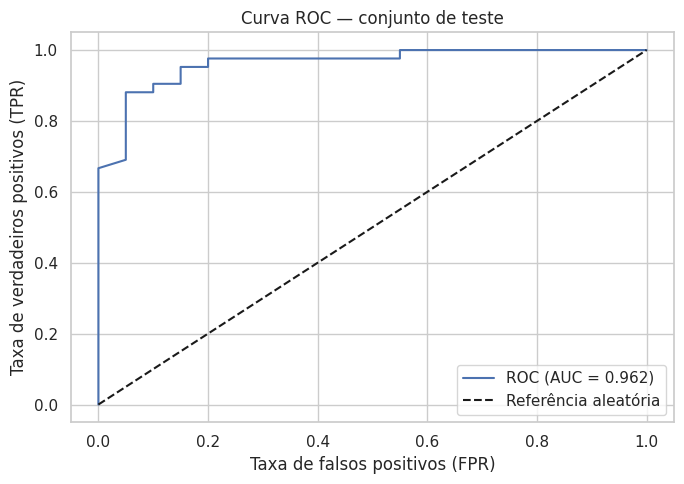

AUC-ROC no teste: 0.9625


In [27]:
auc_roc = roc_auc_score(test_labels, prob_test)
fpr_curve, tpr_curve, thresholds = roc_curve(test_labels, prob_test)

plt.figure(figsize=(7, 5))
plt.plot(fpr_curve, tpr_curve, label=f"ROC (AUC = {auc_roc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Referência aleatória")
plt.xlabel("Taxa de falsos positivos (FPR)")
plt.ylabel("Taxa de verdadeiros positivos (TPR)")
plt.title("Curva ROC — conjunto de teste")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

print(f"AUC-ROC no teste: {auc_roc:.4f}")

## 12. Experimento com diferentes limiares

Assim como no notebook de referência, podemos observar como o limiar altera a classificação. Aqui comparamos 0,25, 0,30 e 0,75 usando o conjunto de validação. O conjunto de teste continua reservado para a avaliação final.

In [28]:
resultados_threshold = []

for limiar in [0.25, 0.30, 0.75]:
    previsoes = (prob_val >= limiar).astype(int)
    cm = confusion_matrix(y_val, previsoes, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    resultados_threshold.append({
        "threshold": limiar,
        "acuracia": accuracy_score(y_val, previsoes),
        "sensibilidade": tp / (tp + fn) if (tp + fn) else 0,
        "especificidade": tn / (tn + fp) if (tn + fp) else 0
    })

display(pd.DataFrame(resultados_threshold).set_index("threshold").style.format("{:.2%}"))

,acuracia,sensibilidade,especificidade
threshold,,,
0.250000,77.42%,100.00%,30.00%
0.300000,77.42%,95.24%,40.00%
0.750000,72.58%,66.67%,85.00%


## 13. Predição de uma amostra

Por fim, usamos uma observação do conjunto de teste para demonstrar a predição. O registro é apresentado com os seis atributos, a classe prevista, a classe real e as probabilidades estimadas.

In [29]:
nova_amostra = X_test.iloc[[0]]
prob_abnormal = modelo.predict_proba(nova_amostra)[0, 1]
classe_prevista = binary_convert(prob_abnormal, THRESHOLD)
classe_real = int(y_test.iloc[0])

print("Atributos da amostra:")
display(nova_amostra)
print("Classe prevista:", "Abnormal" if classe_prevista == 1 else "Normal")
print("Classe real:", "Abnormal" if classe_real == 1 else "Normal")
print(f"Probabilidade estimada de Abnormal: {prob_abnormal:.2%}")

Atributos da amostra:


,pelvic_incidence,pelvic_tilt,lumbar_lordosis_angle,sacral_slope,pelvic_radius,degree_spondylolisthesis
4,49.712859,9.652075,28.317406,40.060784,108.168725,7.918501


Classe prevista: Abnormal
Classe real: Abnormal
Probabilidade estimada de Abnormal: 63.00%


## 14. Conclusão

A esteira contemplou a análise descritiva, limpeza e transformação dos dados, separação em treinamento/validação/teste, treinamento de um classificador, avaliação com matriz de confusão e acurácia, métricas adicionais, curva ROC/AUC e uma predição individual.

A sensibilidade e a especificidade ajudam a entender os tipos de erro do modelo, além da acurácia geral. A escolha do limiar altera o equilíbrio entre falsos positivos e falsos negativos.

**Limitação:** este é um exercício acadêmico com uma base pública. O resultado não deve ser utilizado para diagnóstico ou decisão clínica real.